In [2]:
import os
import numpy as np
import matplotlib.pyplot as plt

def lcg(seed=42, a=21, c=43, m=200, n=20):
    numbers = []
    x = seed # fixed
    for _ in range(n):
        x = (a * x + c) % m
        numbers.append(x)
    return numbers

def get_points(points_2_pairs=20):
    points = {
        'points_1': np.array([
                    [120, 240],
                    [370, 180],
                    [550, 460],
                    [260, 540]
                    ]),
        'points_2': np.reshape(np.array(lcg(n=2*points_2_pairs)),(-1,2))
    }
    return points

[]


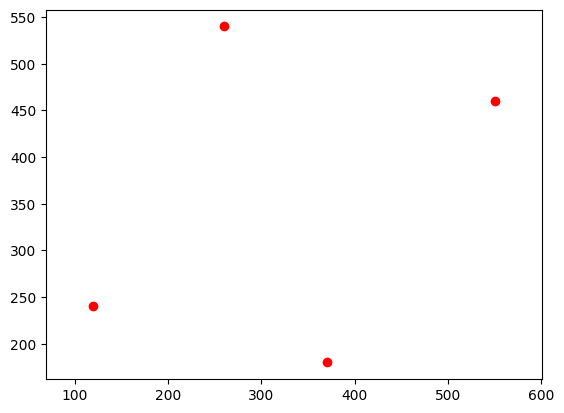

[]


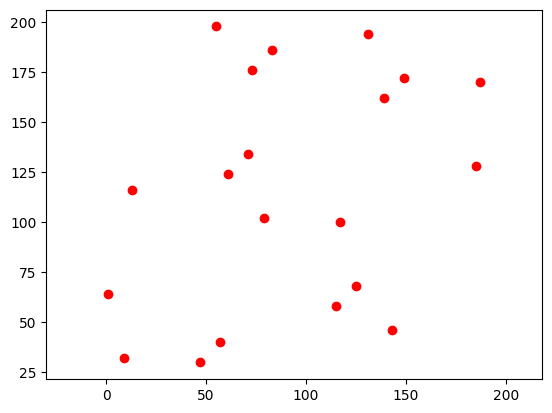

In [3]:
class DelaunayTriangulation:
    def __init__(self, points):
        self.points = points
        self.triangles = []

    # TODO
    def makeDelaunay(self):

        self.triangles = [

        ]

    def plot(self):
        print(self.triangles)
        plt.figure()
        # self.triangles가 비어있으면 아무것도 연결 안 함
        if len(self.triangles) > 0:
            for tri in self.triangles:
                pts = self.points[tri]
                # 삼각형의 세 변을 직접 그림
                for i in range(3):
                    x = [pts[i][0], pts[(i+1)%3][0]]
                    y = [pts[i][1], pts[(i+1)%3][1]]
                    plt.plot(x, y, 'b-')
        # 점 찍기
        plt.scatter(self.points[:, 0], self.points[:, 1], color='red')
        plt.axis('equal')
        plt.show()

for points in get_points().values():
    dt = DelaunayTriangulation(points)
    dt.makeDelaunay()
    dt.plot()


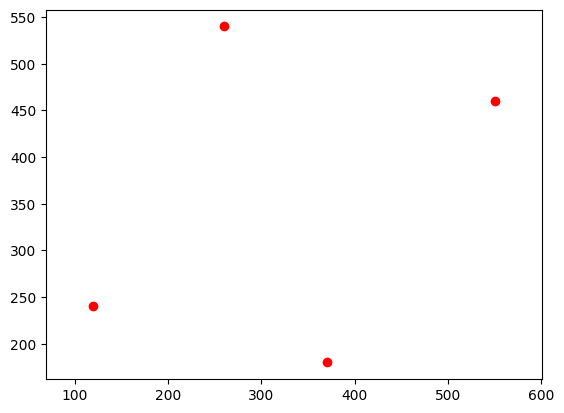

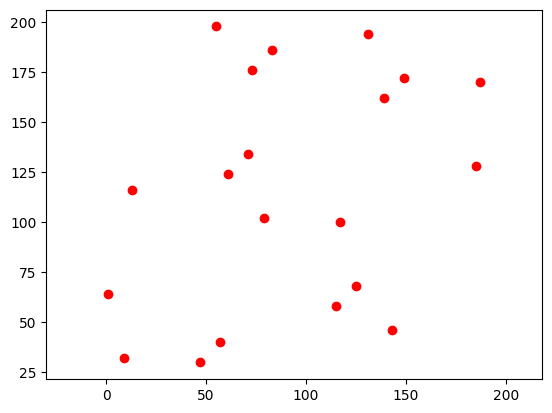

In [5]:
from scipy.spatial import Delaunay


class DelaunayTriangulation:
    def __init__(self, points):
        self.points = points
        self.triangles = []

    def makeDelaunay(self):
        # TODO
        pass

    def plot(self):
        plt.figure()
        self.makeDelaunay()
        # self.triangles가 비어있으면 아무것도 연결 안 함
        if len(self.triangles) > 0:
            for tri in self.triangles:
                pts = self.points[tri]
                # 삼각형의 세 변을 직접 그림
                for i in range(3):
                    x = [pts[i][0], pts[(i+1)%3][0]]
                    y = [pts[i][1], pts[(i+1)%3][1]]
                    plt.plot(x, y, 'b-')
        # 점 찍기
        plt.scatter(self.points[:, 0], self.points[:, 1], color='red')
        plt.axis('equal')
        plt.show()


for points in get_points().values():
    dt = DelaunayTriangulation(points)
    dt.plot()


100%|██████████| 9.91M/9.91M [00:01<00:00, 6.06MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 160kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.52MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 8.12MB/s]


(5000, 784)


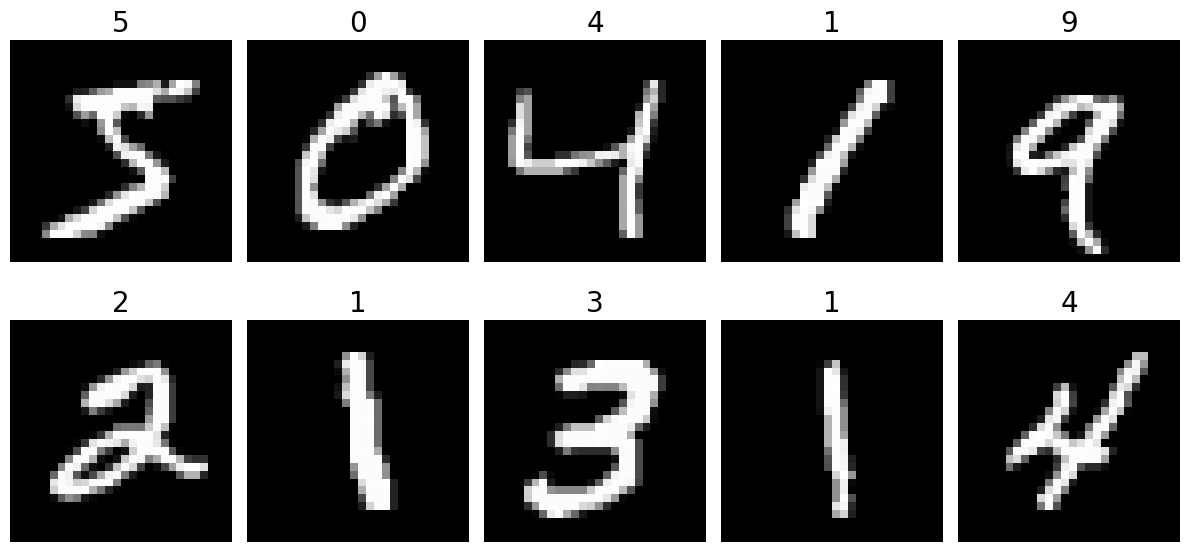

Validation accuracy: 0.938
KNN score: 0.938
k: 1, accuracy: 95.60
k: 2, accuracy: 95.00
k: 3, accuracy: 94.60
k: 4, accuracy: 93.80
k: 5, accuracy: 93.80
k: 6, accuracy: 93.40
k: 7, accuracy: 93.40
k: 8, accuracy: 93.60
k: 9, accuracy: 92.80
k: 10, accuracy: 92.80


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split
import torch
from torchvision import datasets, transforms

# Load MNIST dataset using torchvision
transform = transforms.Compose([transforms.ToTensor()])
mnist_data = datasets.MNIST(root='./data', train=True, download=True, transform=transform)

# Convert the data into numpy arrays
x_digit = mnist_data.data[:5000].numpy()
y_digit = mnist_data.targets[:5000].numpy()

# Reshape x_digit for the KNN classifier
x_digit = x_digit.reshape(-1, 28 * 28)
print(x_digit.shape)

# Visualize some samples
w, h = 2, 5
fig, axes = plt.subplots(w, h)
fig.set_size_inches(12, 6)
for i in range(w * h):
    axes[i // h, i % h].imshow(x_digit[i].reshape(28, 28), cmap='gray')
    axes[i // h, i % h].set_title(y_digit[i], fontsize=20)
    axes[i // h, i % h].axis('off')
plt.tight_layout()
plt.show()

# Split the data into train and validation sets
x_train, x_valid, y_train, y_valid = train_test_split(x_digit, y_digit, stratify=y_digit, random_state=30, test_size=0.1)

# Initialize and train the KNN classifier
knn = KNeighborsClassifier(n_neighbors=5, n_jobs=-1)
knn.fit(x_train, y_train)
prediction = knn.predict(x_valid)

# Calculate accuracy
print("Validation accuracy:", (prediction == y_valid).mean())
print("KNN score:", knn.score(x_valid, y_valid))

# Experiment with different values of k
for k in range(1, 11):
    knn = KNeighborsClassifier(n_neighbors=k, n_jobs=-1)
    knn.fit(x_train, y_train)
    score = knn.score(x_valid, y_valid)
    print('k: %d, accuracy: %.2f' % (k, score * 100))
